# Walk vs Run Image Classifier

A binary image classifier that distinguishes photos of people **running** from people **walking**, built with transfer learning (MobileNetV2) in TensorFlow/Keras.

## 1. Imports

Import TensorFlow/Keras layers and utilities, plus `matplotlib` for plotting and `scikit-learn` for the confusion matrix.

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.layers import Dense , GlobalAveragePooling2D , Rescaling , Dropout , Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import MobileNetV2

## 2. Load Training and Validation Data

Load images from the `walk_or_run_train` folder and split them 80/20 into training and validation sets. `seed=42` makes the split reproducible, and `label_mode='binary'` encodes the two classes as 0/1.

In [2]:
address = "walk_or_run_train"

train = tf.keras.preprocessing.image_dataset_from_directory(
    address,
    image_size = (255,255),
    validation_split = 0.2,
    seed = 42,
    subset = 'training',
    label_mode = 'binary'
)
validation = tf.keras.preprocessing.image_dataset_from_directory(
    address,
    image_size = (255,255),
    validation_split = 0.2,
    seed = 42,
    subset = 'validation',
    label_mode = 'binary'
)


Found 600 files belonging to 2 classes.


Using 480 files for training.
Found 600 files belonging to 2 classes.
Using 120 files for validation.


## 3. Load Test Data

Load the held-out test set from `walk_or_run_test`. `shuffle=False` is important here so that the true labels and the model's predictions stay aligned when building the confusion matrix later.

In [3]:
address_test = "walk_or_run_test"

test = tf.keras.preprocessing.image_dataset_from_directory(
    address_test,
    image_size = (255,255),
    label_mode = 'binary',
    shuffle = False
)

Found 141 files belonging to 2 classes.


## 4. Data Augmentation

Define a small augmentation pipeline (horizontal flip, random brightness, random zoom) that is applied only during training, to make the model more robust and reduce overfitting on this small dataset.

In [4]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomBrightness(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

## 5. Build and Train the Model

Use **MobileNetV2** pretrained on ImageNet as a frozen feature extractor, then add a small classification head on top (`GlobalAveragePooling2D` → `Dropout` → `Dense(1, sigmoid)`). `EarlyStopping` halts training once validation loss stops improving and restores the best weights found.

In [5]:
base = MobileNetV2(input_shape=(255,255,3), include_top=False,weights='imagenet')
base.trainable = False


model = Sequential([
    Input(shape=(255,255,3)),
    data_augmentation,
    Rescaling(1/127.5,offset=-1),
    base,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(1, activation='sigmoid'),
])
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)


early_stop = EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)


model.fit(train,validation_data = validation , epochs = 20 , callbacks=[early_stop])

C:\Users\snid\AppData\Local\Temp\ipykernel_4568\2922805369.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = MobileNetV2(input_shape=(255,255,3), include_top=False,weights='imagenet')


Epoch 1/20


c:\Users\snid\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


15/15 ━━━━━━━━━━━━━━━━━━━━ 14s 750ms/step - accuracy: 0.5188 - loss: 0.7589 - val_accuracy: 0.6500 - val_loss: 0.6178
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 690ms/step - accuracy: 0.6604 - loss: 0.6116 - val_accuracy: 0.7917 - val_loss: 0.5408
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 715ms/step - accuracy: 0.7688 - loss: 0.5196 - val_accuracy: 0.7833 - val_loss: 0.4891
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 681ms/step - accuracy: 0.7771 - loss: 0.4860 - val_accuracy: 0.8083 - val_loss: 0.4589
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 683ms/step - accuracy: 0.8083 - loss: 0.4555 - val_accuracy: 0.8083 - val_loss: 0.4410
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 672ms/step - accuracy: 0.8125 - loss: 0.4051 - val_accuracy: 0.8000 - val_loss: 0.4255
Epoch 7/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 683ms/step - accuracy: 0.8313 - loss: 0.3890 - val_accuracy: 0.8167 - val_loss: 0.4182
Epoch 8/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 677ms/step - accuracy: 0.8458 - loss: 0.3715 - val_accuracy: 0.808

## 6. Evaluate on the Test Set

Report loss and accuracy on the test set, which the model never saw during training.

In [6]:
model.evaluate(test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 431ms/step - accuracy: 0.8227 - loss: 0.3559


[0.3559211194515228, 0.8226950168609619]

## 7. Training History Plot

Continue training and plot train vs. validation accuracy across epochs to visualize learning progress and check for overfitting.

Epoch 1/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 674ms/step - accuracy: 0.9000 - loss: 0.2634 - val_accuracy: 0.8333 - val_loss: 0.3781
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 692ms/step - accuracy: 0.9083 - loss: 0.2442 - val_accuracy: 0.8250 - val_loss: 0.3805
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 685ms/step - accuracy: 0.9167 - loss: 0.2512 - val_accuracy: 0.8333 - val_loss: 0.3786
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 671ms/step - accuracy: 0.9375 - loss: 0.2362 - val_accuracy: 0.8333 - val_loss: 0.3781
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 702ms/step - accuracy: 0.9167 - loss: 0.2336 - val_accuracy: 0.8250 - val_loss: 0.3744
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 717ms/step - accuracy: 0.9083 - loss: 0.2303 - val_accuracy: 0.8250 - val_loss: 0.3786
Epoch 7/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 671ms/step - accuracy: 0.9104 - loss: 0.2412 - val_accuracy: 0.8333 - val_loss: 0.3711
Epoch 8/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 694ms/step - accuracy: 0.9042 - loss: 0.2351 - val_accu

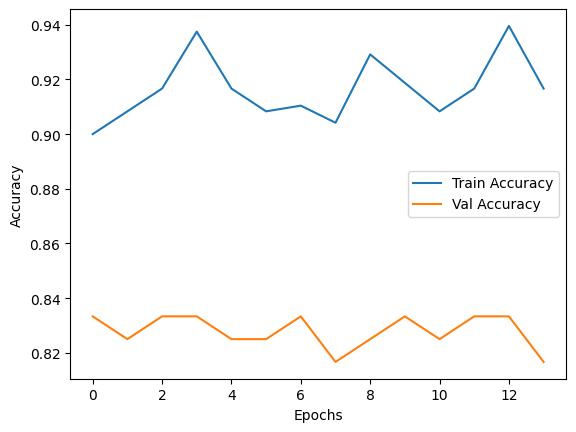

In [7]:
history = model.fit(train,validation_data=validation,epochs=20,callbacks=[early_stop])

plt.plot(history.history['accuracy'],label='Train Accuracy')
plt.plot(history.history['val_accuracy'],label='Val Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## 8. Confusion Matrix

Compare true vs. predicted labels on the test set to see exactly which classes the model confuses (e.g. run misclassified as walk).

5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 574ms/step


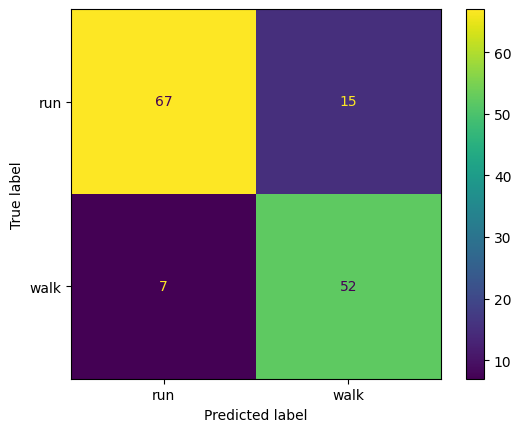

In [8]:
y_true = np.concatenate([y for x,y in test],axis=0)
y_pred = (model.predict(test) > 0.5).astype(int)

cm = confusion_matrix(y_true,y_pred)
ConfusionMatrixDisplay(cm,display_labels=test.class_names).plot()
plt.show()